<a href="https://colab.research.google.com/github/Alejandra300905/NLP_Polarity_of_film_reviews_and_the_problem_of_negation/blob/main/ProyectoClasificacionR_Final_AlejandraB_CarlosM_NathalieL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# R3.1 Polaridad de reseñas de cine y el problema de la negación

### Bitácora de Contribuciones del Equipo

| Etapa | Programó (Implementación) | Revisó (Código y Resultados) | Hizo la Presentación |
| :---: | :--- | :--- | :--- |
| **Etapa 1** | Carlos | Alejandra | Alejandra |
| **Etapa 2** | Alejandra | Nathalie | Carlos |
| **Etapa 3** | Nathalie | Carlos | Nathalie |


### Etapa 1 - **Análisis, representacion y baseline.** Limpieza (etiquetas HTML, puntuación) y división Train, Dev y Test. Baseline: bolsa de palabras de unigramas + Bayes ingenuo

In [ ]:
import os
import tarfile
import pandas as pd
from google.colab import files
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, auc
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler

try:
  import gensim.downloader as api
  print("gemsim ya está instalada.")
except ImportError:
  print("gensim no encontrada. Instalando...")
  !pip install gensim
  import gensim.downloader as api

gemsim ya está instalada.


In [ ]:
tar_filename = 'aclImdb_v1.tar.gz'

# Si no existe la carpeta extraída, procedemos a obtener el archivo
if not os.path.exists('aclImdb'):
    if not os.path.exists(tar_filename):
        print("Por favor, sube tu archivo aclImdb_v1.tar.gz:")
        uploaded = files.upload()
        # Renombrar en caso de que se haya subido con otro nombre similar
        for name in uploaded.keys():
            if 'tar.gz' in name or 'gtarz' in name:
                os.rename(name, tar_filename)
                break

    print("Extrayendo aclImdb_v1.tar.gz...")
    with tarfile.open(tar_filename, 'r:gz') as tar:
        tar.extractall()

def load_imdb_dataset(base_dir):
    data = []
    for split in ['train', 'test']:
        for sentiment in ['pos', 'neg']:
            folder = os.path.join(base_dir, split, sentiment)
            label = 1 if sentiment == 'pos' else 0
            if os.path.exists(folder):
                for filename in os.listdir(folder):
                    if filename.endswith('.txt'):
                        with open(os.path.join(folder, filename), 'r', encoding='utf-8') as f:
                            review = f.read()
                            data.append({'review': review, 'sentiment': label, 'split': split})
    return pd.DataFrame(data)

Por favor, sube tu archivo aclImdb_v1.tar.gz:


Saving aclImdb_v1.tar.gz to aclImdb_v1.tar.gz
Extrayendo aclImdb_v1.tar.gz...


/tmp/ipykernel_4045/2390344328.py:16: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall()


In [ ]:
# Cargar los datos en un DataFrame
df = load_imdb_dataset('aclImdb')

display(df.head())
display(df.info())

,review,sentiment,split
0,Fever Pitch is a fun enough movie. It has a lo...,1,train
1,What more can be said? I have not been this fa...,1,train
2,No rubbish - no where even near rubbish. Not a...,1,train
3,I saw this movie on the BIFFF Festival in Brus...,1,train
4,"Even this early in his career, Capra was quite...",1,train


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  int64 
 2   split      50000 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.1+ MB


None

In [ ]:
# Mostrar los valores únicos y la cantidad de registros para cada split
display(df['split'].value_counts())

,count
split,
train,25000
test,25000


count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: n_palabras, dtype: float64


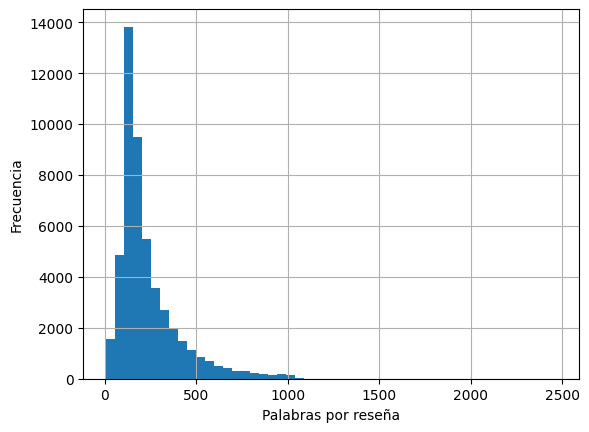

Con <br />: 29200


In [ ]:
# Balance de clases y tamaño de cada partición
#print(df.groupby(["split", "sentiment"]).size().unstack())

# Longitud de reseñas (en palabras)
df["n_palabras"] = df["review"].str.split().str.len()
print(df["n_palabras"].describe())

df["n_palabras"].hist(bins=50)
plt.xlabel("Palabras por reseña"); plt.ylabel("Frecuencia")
plt.show()

# ¿Cuántas reseñas tienen etiquetas HTML?
print("Con <br />:", df["review"].str.contains("<br", regex=False).sum())

In [ ]:
def limpiar(texto):
    texto = re.sub(r"<[^>]+>", " ", texto)      # quita etiquetas HTML
    texto = texto.lower()                        # minúsculas
    texto = re.sub(r"[^a-z' ]", " ", texto)      # quita puntuación, números y símbolos (conserva ')
    texto = re.sub(r"\s+", " ", texto).strip()   # colapsa espacios
    return texto

df["clean"] = df["review"].apply(limpiar)
print(df.loc[1, "review"][:200])
print(df.loc[1, "clean"][:200])

What more can be said? I have not been this fascinated with a young actress since Cate Blanchett burst upon the scene over ten years ago. And although both Blanchett and Blunt have played Queens now( 
what more can be said i have not been this fascinated with a young actress since cate blanchett burst upon the scene over ten years ago and although both blanchett and blunt have played queens now see


In [ ]:
df.head()

,review,sentiment,split,n_palabras,clean
0,Fever Pitch is a fun enough movie. It has a lo...,1,train,111,fever pitch is a fun enough movie it has a lot...
1,What more can be said? I have not been this fa...,1,train,866,what more can be said i have not been this fas...
2,No rubbish - no where even near rubbish. Not a...,1,train,112,no rubbish no where even near rubbish not an o...
3,I saw this movie on the BIFFF Festival in Brus...,1,train,108,i saw this movie on the bifff festival in brus...
4,"Even this early in his career, Capra was quite...",1,train,137,even this early in his career capra was quite ...


In [ ]:
# Data split
train_full = df[df["split"] == "train"]
test = df[df["split"] == "test"]      # se queda intacto hasta el final

train, dev = train_test_split(
    train_full,
    test_size=0.2,
    stratify=train_full["sentiment"],
    random_state=42
)

print(len(train), len(dev), len(test))   # 20000, 5000, 25000

20000 5000 25000


In [ ]:
vectorizer = CountVectorizer(
    ngram_range=(1,1),
    token_pattern=r"[a-z]+(?:'[a-z]+)*",   # conserva didn't, isn't...
    min_df=2
)
X_train = vectorizer.fit_transform(train["clean"])   # fit SOLO con train
X_dev   = vectorizer.transform(dev["clean"])

y_train, y_dev = train["sentiment"], dev["sentiment"]
print("Vocabulario:", len(vectorizer.vocabulary_))

nb = MultinomialNB(alpha=1.0)
nb.fit(X_train, y_train)

Vocabulario: 42845


MultinomialNB()

In [ ]:
def evaluar(modelo, X, y, nombre):
    pred = modelo.predict(X)
    proba = modelo.predict_proba(X)[:, 1]
    print(f"── {nombre} ──")
    print(f"Exactitud: {accuracy_score(y, pred):.4f}")
    print(f"F1:        {f1_score(y, pred):.4f}")
    print(f"AUC-ROC:   {roc_auc_score(y, proba):.4f}")
    return pred

pred_dev = evaluar(nb, X_dev, y_dev, "Dev")
print(classification_report(y_dev, pred_dev, target_names=["neg", "pos"]))

# Test: úsalo UNA sola vez, cuando el baseline esté definitivo
#pred_test = evaluar(nb, X_test, y_test, "Test")

── Dev ──
Exactitud: 0.8468
F1:        0.8421
AUC-ROC:   0.9187
              precision    recall  f1-score   support

         neg       0.83      0.88      0.85      2500
         pos       0.87      0.82      0.84      2500

    accuracy                           0.85      5000
   macro avg       0.85      0.85      0.85      5000
weighted avg       0.85      0.85      0.85      5000



In [ ]:
# Seleccionamos una reseña del conjunto de desarrollo (por ejemplo, la primera)
indice_ejemplo = 0
texto_original = dev["review"].iloc[indice_ejemplo]
texto_limpio = dev["clean"].iloc[indice_ejemplo]
etiqueta_real = dev["sentiment"].iloc[indice_ejemplo]

# Transformamos el texto con el vectorizer para que tenga el formato adecuado
vector_ejemplo = X_dev[indice_ejemplo]

# Obtenemos las probabilidades de cada clase
probabilidades = nb.predict_proba(vector_ejemplo)[0]
prediccion = nb.predict(vector_ejemplo)[0]

print("=== TEXTO DE LA RESEÑA ===")
print(texto_original[:500] + ("..." if len(texto_original) > 500 else ""))
print("\n" + "="*30)
print(f"Etiqueta Real: {'Positivo (1)' if etiqueta_real == 1 else 'Negativo (0)'}")
print(f"Predicción del Modelo: {'Positivo (1)' if prediccion == 1 else 'Negativo (0)'}")
print("="*30)
print(f"Probabilidad de ser NEGATIVA (0): {probabilidades[0]:.6f} ({probabilidades[0]*100:.4f}%)")
print(f"Probabilidad de ser POSITIVA (1): {probabilidades[1]:.6f} ({probabilidades[1]*100:.4f}%)")


=== TEXTO DE LA RESEÑA ===
This- and not a certain slightly overrated Southern Soap Opera-was the greatest epic to come out of Hollywoods greatest year, 1939.I will not not restate the obvious-Cary Grant,Victor McLaglen( who WAS a Bengal Lancer), and Douglas Fairbanks Jr. give superb comic performances.However, I want to note two other, less understood elements of this masterpiece. The Magnificent final battle sequence, as the wonderful Sam Jaffe climbs laboriously up to the pinnacle of the temple to blow his bugle and wa...

Etiqueta Real: Positivo (1)
Predicción del Modelo: Positivo (1)
Probabilidad de ser NEGATIVA (0): 0.000000 (0.0000%)
Probabilidad de ser POSITIVA (1): 1.000000 (100.0000%)


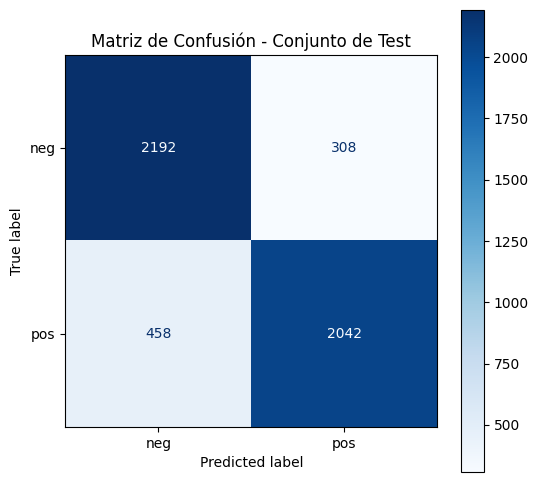

Verdaderos Negativos (TN): 2192
Falsos Positivos (FP): 308
Falsos Negativos (FN): 458
Verdaderos Positivos (TP): 2042


In [ ]:
# Matriz confusion Bayes-Ingenuo
cm = confusion_matrix(y_dev, pred_dev)

# Crear la visualización de la matriz de confusión
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["neg", "pos"])

# Graficar la matriz
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap=plt.cm.Blues, values_format='d')
plt.title("Matriz de Confusión - Conjunto de Test")
plt.show()

# Imprimir también los valores numéricos directos
tn, fp, fn, tp = cm.ravel()
print(f"Verdaderos Negativos (TN): {tn}")
print(f"Falsos Positivos (FP): {fp}")
print(f"Falsos Negativos (FN): {fn}")
print(f"Verdaderos Positivos (TP): {tp}")


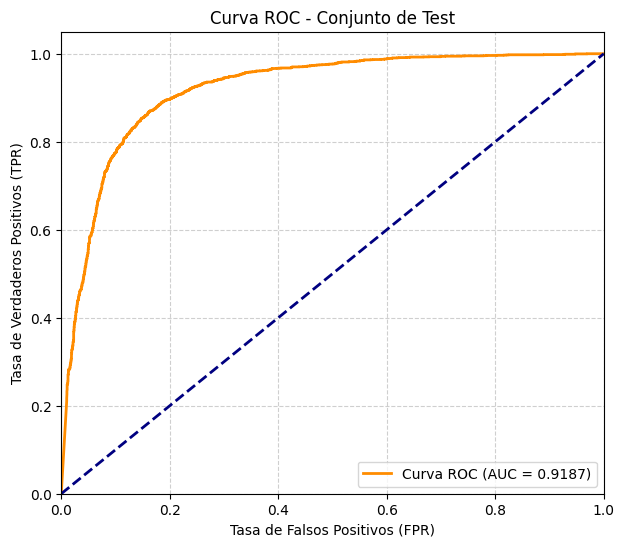

In [ ]:
# Curva ROC Bayes-Ingenuo
proba_dev = nb.predict_proba(X_dev)[:, 1]

fpr, tpr, _ = roc_curve(y_dev, proba_dev)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC - Conjunto de Test')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


### Etapa 2 - **Primera aproximación**. TF-IDF de unigramas y bigramas + regresión logística, con y sin marcado de negación

2.1 Modelo A: TF-IDF (unigramas + bigramas) + Regresión Logística, **sin** marcado de negación

In [ ]:
# TF-IDF con unigramas y bigramas sobre el texto limpio de la Etapa 1
tfidf_A = TfidfVectorizer(
    ngram_range=(1, 2),
    token_pattern=r"[a-z]+(?:'[a-z]+)*",   # conserva didn't, isn't...
    min_df=2,
    sublinear_tf=True
)
XA_train = tfidf_A.fit_transform(train["clean"])   # fit SOLO con train
XA_dev   = tfidf_A.transform(dev["clean"])
print("Vocabulario (uni+bigramas):", len(tfidf_A.vocabulary_))

# Elegimos C (regularización) con el conjunto Dev
mejor_C_A, mejor_auc_A = 500, -1
'''
for C in [1, 5, 10, 50, 100, 200, 500]:
    m = LogisticRegression(C=C, max_iter=5000, solver="liblinear")
    m.fit(XA_train, y_train)
    auc_dev = roc_auc_score(y_dev, m.predict_proba(XA_dev)[:, 1])
    print(f"C={C:<5} AUC Dev = {auc_dev:.4f}")
    if auc_dev > mejor_auc_A:
        mejor_C_A, mejor_auc_A = C, auc_dev
print("Mejor C:", mejor_C_A)
'''
lr_A = LogisticRegression(C=mejor_C_A, max_iter=10000, solver="liblinear")
lr_A.fit(XA_train, y_train)
pred_dev_A = evaluar(lr_A, XA_dev, y_dev, "Modelo A - Dev (sin negación)")
print(classification_report(y_dev, pred_dev_A, target_names=["neg", "pos"]))

Vocabulario (uni+bigramas): 364375
── Modelo A - Dev (sin negación) ──
Exactitud: 0.9128
F1:        0.9133
AUC-ROC:   0.9702
              precision    recall  f1-score   support

         neg       0.92      0.91      0.91      2500
         pos       0.91      0.92      0.91      2500

    accuracy                           0.91      5000
   macro avg       0.91      0.91      0.91      5000
weighted avg       0.91      0.91      0.91      5000



### Interpretación del Modelo A

En esta etapa se utilizó TF-IDF con unigramas y bigramas para representar numéricamente las reseñas. Posteriormente, entrenamos una regresión logística para clasificarlas como positivas o negativas.

El uso de bigramas permite considerar pares de palabras consecutivas y capturar expresiones como "not good".

2.2 Marcado de negación

In [ ]:
NEGACIONES = {"not", "no", "never", "none", "nobody", "nothing", "nowhere",
              "neither", "nor", "cannot", "without", "hardly", "barely", "scarcely"}
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)*|[.,;:!?()]")   # palabras o signos de puntuación
PUNTUACION = set(".,;:!?()")

def es_negacion(tok):
    return tok in NEGACIONES or tok.endswith("n't")      # didn't, isn't, don't, can't...

def marcar_negacion(texto):
    texto = re.sub(r"<[^>]+>", " ", texto).lower()
    salida, en_negacion = [], False
    for tok in TOKEN_RE.findall(texto):
        if tok in PUNTUACION:                            # la puntuación cierra el alcance
            en_negacion = False
            continue                                     # y se descarta
        salida.append("NEG_" + tok if en_negacion else tok)
        if es_negacion(tok):                             # a partir de aquí, se marca
            en_negacion = True
    return " ".join(salida)

# Ejemplos para verificar la regla
ejemplos = [
    "This movie is not good, it was a waste.",
    "I didn't like the acting or the plot. Great music!",
    "Not bad at all<br />but never boring; fun",
]
for e in ejemplos:
    print("ORIGINAL:", e)
    print("MARCADO :", marcar_negacion(e), "\n")

df["clean_neg"] = df["review"].apply(marcar_negacion)
train = df.loc[train.index];
dev = df.loc[dev.index];
test = df.loc[test.index]   # mismas particiones, con la nueva columna
print(dev["clean_neg"].iloc[0][:300])

ORIGINAL: This movie is not good, it was a waste.
MARCADO : this movie is not NEG_good it was a waste 

ORIGINAL: I didn't like the acting or the plot. Great music!
MARCADO : i didn't NEG_like NEG_the NEG_acting NEG_or NEG_the NEG_plot great music 

ORIGINAL: Not bad at all<br />but never boring; fun
MARCADO : not NEG_bad NEG_at NEG_all NEG_but NEG_never NEG_boring fun 

this and not NEG_a NEG_certain NEG_slightly NEG_overrated NEG_southern NEG_soap NEG_opera NEG_was NEG_the NEG_greatest NEG_epic NEG_to NEG_come NEG_out NEG_of NEG_hollywoods NEG_greatest NEG_year i will not NEG_not NEG_restate NEG_the NEG_obvious NEG_cary NEG_grant victor mclaglen who was a bengal l


### Marcado explícito de negación

La función identifica palabras de negación y marca los tokens siguientes con el prefijo `NEG_` hasta encontrar un signo de puntuación reconocido.

Esta transformación busca distinguir palabras como `good` y `NEG_good`.

2.3 Modelo B: TF-IDF (unigramas + bigramas) + Regresión Logística, **con** marcado de negación

In [ ]:
tfidf_B = TfidfVectorizer(
    ngram_range=(1, 2),
    token_pattern=r"[A-Za-z_]+(?:'[a-z]+)*",   # acepta NEG_palabra
    lowercase=False,                            # ya está en minúsculas; así no se altera NEG_
    min_df=2,
    sublinear_tf=True
)
XB_train = tfidf_B.fit_transform(train["clean_neg"])   # fit SOLO con train
XB_dev   = tfidf_B.transform(dev["clean_neg"])
print("Vocabulario (uni+bigramas, con NEG_):", len(tfidf_B.vocabulary_))
mejor_C_B, mejor_auc_B = 200, -1
"""
for C in [1, 5, 10, 50, 100, 200]:
    m = LogisticRegression(C=C, max_iter=5000, solver="liblinear")
    m.fit(XB_train, y_train)
    auc_dev = roc_auc_score(y_dev, m.predict_proba(XB_dev)[:, 1])
    print(f"C={C:<5} AUC Dev = {auc_dev:.4f}")
    if auc_dev > mejor_auc_B:
        mejor_C_B, mejor_auc_B = C, auc_dev
print("Mejor C:", mejor_C_B)
"""
lr_B = LogisticRegression(C=mejor_C_B, max_iter=10000, solver="liblinear")
lr_B.fit(XB_train, y_train)
pred_dev_B = evaluar(lr_B, XB_dev, y_dev, "Modelo B - Dev (con negación)")
print(classification_report(y_dev, pred_dev_B, target_names=["neg", "pos"]))

Vocabulario (uni+bigramas, con NEG_): 392734
── Modelo B - Dev (con negación) ──
Exactitud: 0.9124
F1:        0.9131
AUC-ROC:   0.9705
              precision    recall  f1-score   support

         neg       0.92      0.90      0.91      2500
         pos       0.91      0.92      0.91      2500

    accuracy                           0.91      5000
   macro avg       0.91      0.91      0.91      5000
weighted avg       0.91      0.91      0.91      5000



### Entrenamiento del Modelo B

Se aplica TF-IDF al texto con negaciones marcadas y se entrena una regresión logística. Se mantiene el mismo procedimiento de selección de C utilizado en el Modelo A para facilitar la comparación.

2.4 Comparación: Baseline vs Modelo A vs Modelo B

In [ ]:
def metricas(modelo, X, y):
    pred = modelo.predict(X)
    proba = modelo.predict_proba(X)[:, 1]
    return {"Exactitud": accuracy_score(y, pred),
            "F1": f1_score(y, pred),
            "AUC-ROC": roc_auc_score(y, proba)}

resultados = {
    "Baseline: BoW + Naive Bayes":         (metricas(nb,   X_dev,  y_dev), metricas(nb,   X_dev,  y_dev)),
    "A: TF-IDF 1-2g + LR (sin negación)":  (metricas(lr_A, XA_dev, y_dev), metricas(lr_A, XA_dev, y_dev)),
    "B: TF-IDF 1-2g + LR (con negación)":  (metricas(lr_B, XB_dev, y_dev), metricas(lr_B, XB_dev, y_dev)),
}

filas = []
for nombre, (m_dev, m_test) in resultados.items():
    fila = {"Modelo": nombre}
    fila.update({f"Dev {k}": v for k, v in m_dev.items()})
    filas.append(fila)

tabla = pd.DataFrame(filas).set_index("Modelo").round(4)
display(tabla)

# Efecto del marcado de negación (B - A) en Dev
print("\nMejora por marcado de negación (B - A) en Dev:")
for k in ["Exactitud", "F1", "AUC-ROC"]:
    d = resultados["B: TF-IDF 1-2g + LR (con negación)"][1][k] - resultados["A: TF-IDF 1-2g + LR (sin negación)"][1][k]
    print(f"  {k:<10}: {d:+.4f}")

,Dev Exactitud,Dev F1,Dev AUC-ROC
Modelo,,,
Baseline: BoW + Naive Bayes,0.8468,0.8421,0.9187
A: TF-IDF 1-2g + LR (sin negación),0.9128,0.9133,0.9702
B: TF-IDF 1-2g + LR (con negación),0.9124,0.9131,0.9705



Mejora por marcado de negación (B - A) en Dev:
  Exactitud : -0.0004
  F1        : -0.0002
  AUC-ROC   : +0.0003


### Interpretación de resultados

El Modelo A y el Modelo B superan al baseline en las métricas evaluadas. El Modelo B obtiene una mejora pequeña respecto al Modelo A en F1 y AUC-ROC.

Estos resultados sugieren que el marcado explícito de negación aporta una mejora adicional en este conjunto de datos.

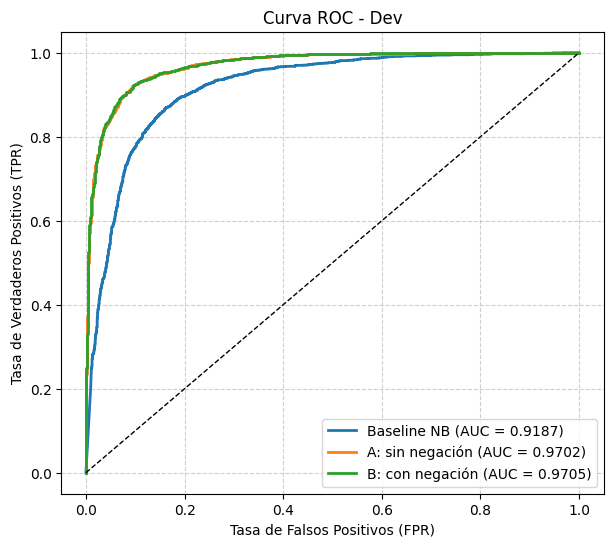

In [ ]:
plt.figure(figsize=(7, 6))
for nombre, modelo, X in [("Baseline NB", nb, X_dev),
                          ("A: sin negación", lr_A, XA_dev),
                          ("B: con negación", lr_B, XB_dev)]:
    fpr, tpr, _ = roc_curve(y_dev, modelo.predict_proba(X)[:, 1])
    plt.plot(fpr, tpr, lw=2, label=f"{nombre} (AUC = {auc(fpr, tpr):.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("Tasa de Falsos Positivos (FPR)"); plt.ylabel("Tasa de Verdaderos Positivos (TPR)")
plt.title("Curva ROC - Dev"); plt.legend(loc="lower right"); plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

### Curva ROC

Se compara la tasa de verdaderos positivos con la tasa de falsos positivos para distintos umbrales. El AUC resume la capacidad de discriminación de cada modelo.

El Modelo B presenta el AUC más alto, aunque la diferencia respecto al Modelo A es pequeña.

###Etapa 3- **Mejora**. Promedio de vectores Word2vec preentrenados + MLP; comparación con la Etapa 2

**Idea:** en lugar de contar palabras (BoW / TF-IDF), representamos cada palabra con un vector denso de 300 dimensiones
(Word2vec de Google News) y cada reseña como el **promedio** de los vectores de sus palabras.
Sobre esa representación entrenamos un MLP.

In [ ]:
# Semillas para reproducibilidad
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Word2vec de Google News (3 millones de palabras, 300 dimensiones).
# La primera vez descarga ~1.6 GB, puede tardar unos minutos.
w2v = api.load("word2vec-google-news-300")
print("Vocabulario:", len(w2v.key_to_index), "| Dimensión:", w2v.vector_size)

[==================================================] 100.0% 1662.8/1662.8MB downloaded
Vocabulario: 3000000 | Dimensión: 300


3.1 Representación de las reseñas: promedio de vectores Word2vec

Se usa el texto limpio de la Etapa 1 (`clean`), ya que Word2vec no contiene tokens como `NEG_good`. Las palabras que no existen en Word2vec se ignoran. Se usan las mismas particiones Train / Dev / Test de las etapas anteriores y se estandarizan los vectores (ajustando el escalador **solo** con Train).

In [ ]:
def vector_promedio(texto):
    """Promedia los vectores Word2vec de las palabras de una reseña.
    Ignora palabras fuera del vocabulario; si no hay ninguna, regresa ceros."""
    vectores = [w2v[t] for t in texto.split() if t in w2v.key_to_index]
    if len(vectores) == 0:
        return np.zeros(w2v.vector_size, dtype=np.float32)
    return np.mean(vectores, axis=0)

# Matrices de entrada
Xw_train = np.vstack([vector_promedio(t) for t in train["clean"]])
Xw_dev   = np.vstack([vector_promedio(t) for t in dev["clean"]])

# Estandarización: fit SOLO con train
scaler = StandardScaler()
Xw_train = scaler.fit_transform(Xw_train)
Xw_dev   = scaler.transform(Xw_dev)

print("Train:", Xw_train.shape, "| Dev:", Xw_dev.shape)

Train: (20000, 300) | Dev: (5000, 300)


3.2 Modelo C: Word2vec promedio + MLP

Se entrena un MLP con dos capas ocultas (ReLU + Dropout) y una salida sigmoide. Se usa Dev para monitorear el entrenamiento y detenerlo cuando deja de mejorar; Test no se utiliza aquí.

In [ ]:
# Diccionario con distintas arquitecturas de MLP a probar
arquitecturas = {
    "MLP_256_64": [
        layers.Input(shape=(300,)),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid")
    ],
    "MLP_128_32": [
        layers.Input(shape=(300,)),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(1, activation="sigmoid")
    ],
    "MLP_512_256_64": [
        layers.Input(shape=(300,)),
        layers.Dense(512, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(1, activation="sigmoid")
    ]
}

modelos_entrenados = {}

# Iterar sobre las distintas arquitecturas definidas
for nombre, capas in arquitecturas.items():
    print(f"\n=== Entrenando arquitectura: {nombre} ===")

    # Fijar semillas antes de crear cada modelo para reproducibilidad
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    mlp_temp = keras.Sequential(capas)
    mlp_temp.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=[keras.metrics.AUC(name="roc_auc")]
        )

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    historial = mlp_temp.fit(
        Xw_train, y_train.values,
        validation_data=(Xw_dev, y_dev.values),
        epochs=50,
        batch_size=128,
        callbacks=[early_stop],
        verbose=1
    )

    modelos_entrenados[nombre] = mlp_temp


=== Entrenando arquitectura: MLP_256_64 ===
Epoch 1/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - loss: 0.4256 - roc_auc: 0.8874 - val_loss: 0.3531 - val_roc_auc: 0.9273
Epoch 2/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.3463 - roc_auc: 0.9270 - val_loss: 0.3410 - val_roc_auc: 0.9319
Epoch 3/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.3225 - roc_auc: 0.9373 - val_loss: 0.3388 - val_roc_auc: 0.9327
Epoch 4/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.3053 - roc_auc: 0.9438 - val_loss: 0.3348 - val_roc_auc: 0.9347
Epoch 5/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.2937 - roc_auc: 0.9482 - val_loss: 0.3377 - val_roc_auc: 0.9336
Epoch 6/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.2827 - roc_auc: 0.9518 - val_loss: 0.3361 - val_roc_auc: 0.9352
Epoch 7/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.2676 - roc_auc: 0.9568 - val_loss: 0.3386 - val_roc_auc: 0.9341
Epoch 8/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.258

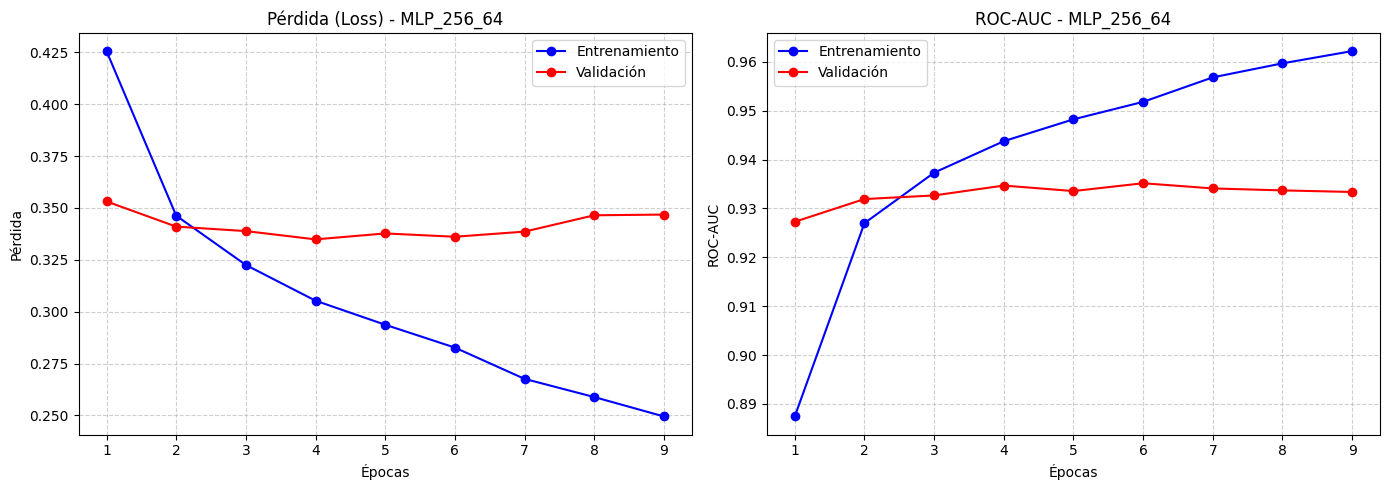

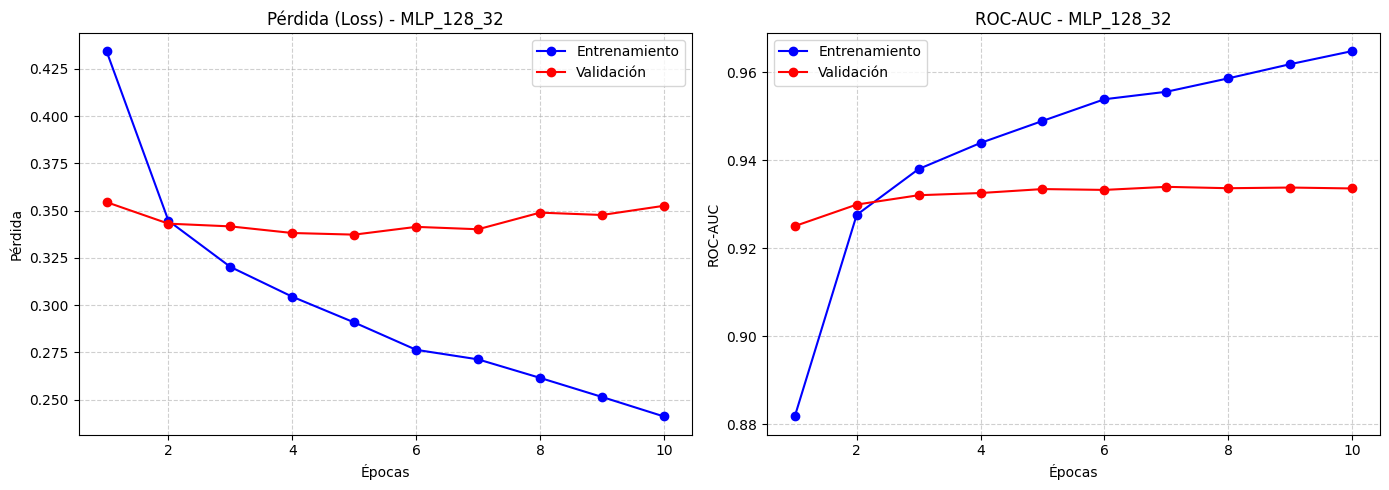

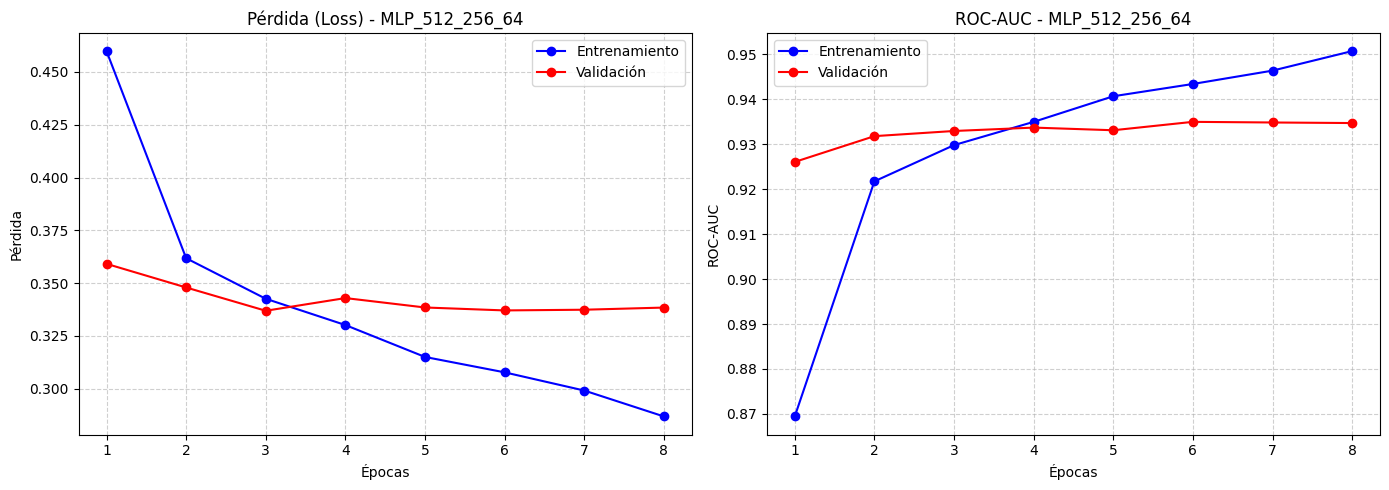

In [ ]:
def graficar_historial(historial_modelo, nombre_modelo="Modelo"):
    """Grafica la pérdida y la métrica ROC-AUC de entrenamiento y validación."""
    # Extraer el diccionario de métricas del objeto History
    if hasattr(historial_modelo, 'history') and hasattr(historial_modelo.history, 'history'):
        hist = historial_modelo.history.history
    elif hasattr(historial_modelo, 'history') and isinstance(historial_modelo.history, dict):
        hist = historial_modelo.history
    elif isinstance(historial_modelo, dict):
        hist = historial_modelo
    else:
        print(f"No se pudieron extraer las métricas de {nombre_modelo}.")
        return

    epochs = range(1, len(hist['loss']) + 1)

    plt.figure(figsize=(14, 5))

    # Gráfico de Pérdida (Loss)
    plt.subplot(1, 2, 1)
    plt.plot(epochs, hist['loss'], 'bo-', label='Entrenamiento')
    plt.plot(epochs, hist['val_loss'], 'ro-', label='Validación')
    plt.title(f'Pérdida (Loss) - {nombre_modelo}')
    plt.xlabel('Épocas')
    plt.ylabel('Pérdida')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)

    # Gráfico de ROC-AUC
    plt.subplot(1, 2, 2)
    if 'roc_auc' in hist:
        plt.plot(epochs, hist['roc_auc'], 'bo-', label='Entrenamiento')
        plt.plot(epochs, hist['val_roc_auc'], 'ro-', label='Validación')
        plt.title(f'ROC-AUC - {nombre_modelo}')
        plt.ylabel('ROC-AUC')
    elif 'accuracy' in hist:
        plt.plot(epochs, hist['accuracy'], 'bo-', label='Entrenamiento')
        plt.plot(epochs, hist['val_accuracy'], 'ro-', label='Validación')
        plt.title(f'Exactitud (Accuracy) - {nombre_modelo}')
        plt.ylabel('Exactitud')
    else:
        print(f"No se encontraron métricas de rendimiento conocidas en {nombre_modelo}.")

    plt.xlabel('Épocas')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

# Graficar de forma separada el historial de cada arquitectura entrenada
if 'modelos_entrenados' in globals() and modelos_entrenados:
    for nombre, modelo in modelos_entrenados.items():
        if hasattr(modelo, 'history') and modelo.history is not None:
            graficar_historial(modelo, nombre)
        else:
            print(f"El modelo {nombre} no contiene historial de entrenamiento guardado.")
elif 'historial' in globals():
    graficar_historial(historial, "Modelo de Referencia")
else:
    print("No se encontraron modelos entrenados ni variables de historial disponibles para graficar.")

3.3 Evaluación del Modelo C en Dev

In [ ]:
def metricas_keras(modelo, X, y):
    """Mismas métricas que `metricas()` de la Etapa 2, pero para un modelo de Keras."""
    proba = modelo.predict(X, verbose=0).ravel()
    pred  = (proba >= 0.5).astype(int)
    return {"Exactitud": accuracy_score(y, pred),
            "F1": f1_score(y, pred),
            "AUC-ROC": roc_auc_score(y, proba)}

# Guardamos de forma segura el mejor modelo entrenado en la variable de referencia 'mlp'
if 'modelos_entrenados' in globals() and "MLP_512_256_64" in modelos_entrenados:
    mlp = modelos_entrenados["MLP_512_256_64"]
    pred_dev_C = (mlp.predict(Xw_dev, verbose=0).ravel() >= 0.5).astype(int)
    print("Métricas de la mejor arquitectura (MLP_512_256_64) en Dev:")
    print({k: round(v, 4) for k, v in metricas_keras(mlp, Xw_dev, y_dev).items()})
    print("\nReporte de Clasificación:")
    print(classification_report(y_dev, pred_dev_C, target_names=["neg", "pos"]))
else:
    print("Error: El diccionario 'modelos_entrenados' o la arquitectura 'MLP_512_256_64' no se encuentran en el kernel.")

Métricas de la mejor arquitectura (MLP_512_256_64) en Dev:
{'Exactitud': 0.858, 'F1': 0.8618, 'AUC-ROC': np.float64(0.933)}

Reporte de Clasificación:
              precision    recall  f1-score   support

         neg       0.88      0.83      0.85      2500
         pos       0.84      0.89      0.86      2500

    accuracy                           0.86      5000
   macro avg       0.86      0.86      0.86      5000
weighted avg       0.86      0.86      0.86      5000



3.4 Comparación con la Etapa 2: Baseline vs Modelo A vs Modelo B vs Modelo C


In [ ]:
# Agregamos el Modelo C (solo métricas de Dev)
resultados["C: Word2vec promedio + MLP"] = metricas_keras(mlp, Xw_dev, y_dev)

filas = []
for nombre, datos in resultados.items():
    fila = {"Modelo": nombre}
    # Si 'datos' es una tupla, el primer elemento es Dev
    if isinstance(datos, tuple):
        m_dev = datos[0]
    else:
        m_dev = datos

    fila.update({f"Dev {k}": v for k, v in m_dev.items()})
    filas.append(fila)

tabla_final = pd.DataFrame(filas).set_index("Modelo").round(4)
display(tabla_final)

# Diferencia de C respecto al mejor modelo de la Etapa 2 (B) en Dev
print("\nDiferencia C - B en Dev:")

# Extraer de forma segura las métricas de Dev para B y C
met_B = resultados["B: TF-IDF 1-2g + LR (con negación)"][0] if isinstance(resultados["B: TF-IDF 1-2g + LR (con negación)"], tuple) else resultados["B: TF-IDF 1-2g + LR (con negación)"]
met_C = resultados["C: Word2vec promedio + MLP"]

for k in ["Exactitud", "F1", "AUC-ROC"]:
    d = met_C[k] - met_B[k]
    print(f"  {k:<10}: {d:+.4f}")

,Dev Exactitud,Dev F1,Dev AUC-ROC
Modelo,,,
Baseline: BoW + Naive Bayes,0.8468,0.8421,0.9187
A: TF-IDF 1-2g + LR (sin negación),0.9128,0.9133,0.9702
B: TF-IDF 1-2g + LR (con negación),0.9124,0.9131,0.9705
C: Word2vec promedio + MLP,0.8580,0.8618,0.9330



Diferencia C - B en Dev:
  Exactitud : -0.0544
  F1        : -0.0514
  AUC-ROC   : -0.0375


### Curva ROC comparativa


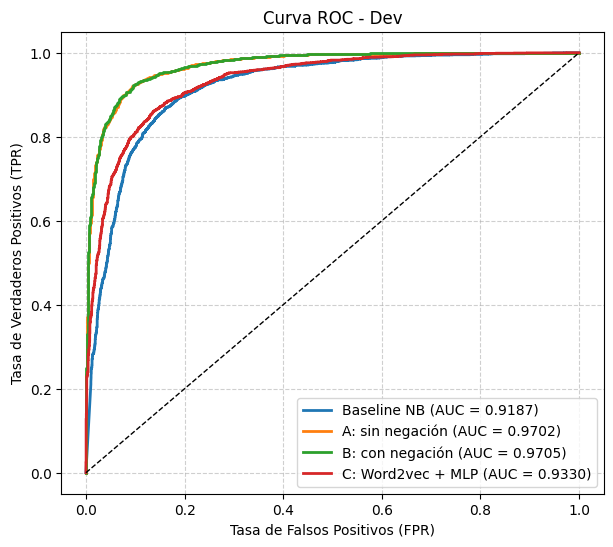

In [ ]:
plt.figure(figsize=(7, 6))
for nombre, proba in [
    ("Baseline NB",       nb.predict_proba(X_dev)[:, 1]),
    ("A: sin negación",   lr_A.predict_proba(XA_dev)[:, 1]),
    ("B: con negación",   lr_B.predict_proba(XB_dev)[:, 1]),
    ("C: Word2vec + MLP", mlp.predict(Xw_dev, verbose=0).ravel()),
]:
    fpr, tpr, _ = roc_curve(y_dev, proba)
    plt.plot(fpr, tpr, lw=2, label=f"{nombre} (AUC = {auc(fpr, tpr):.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("Tasa de Falsos Positivos (FPR)"); plt.ylabel("Tasa de Verdaderos Positivos (TPR)")
plt.title("Curva ROC - Dev")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

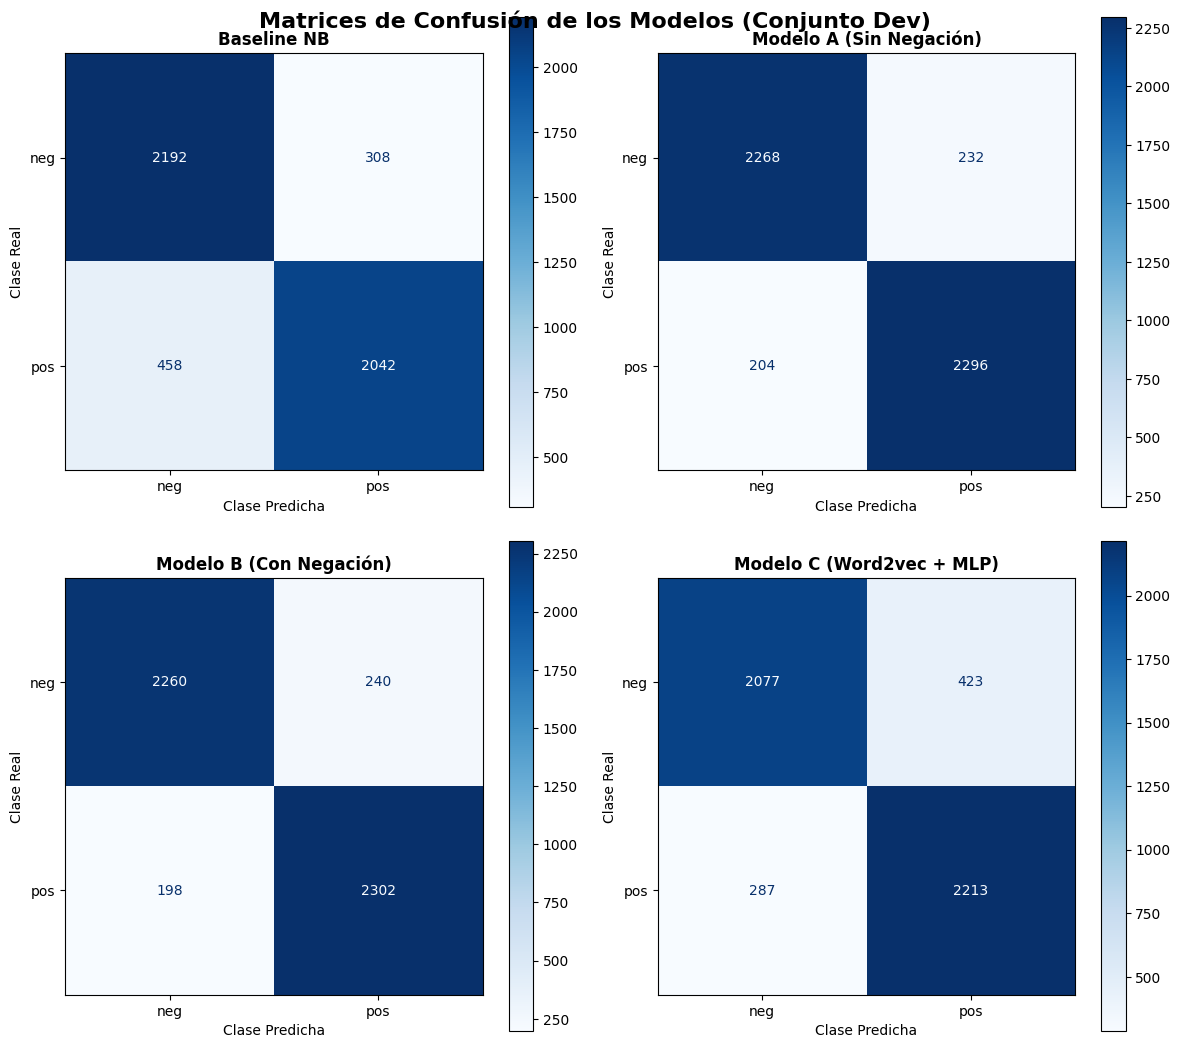

In [ ]:
# 1. Obtener predicciones en Dev para todos los modelos
pred_NB = nb.predict(X_dev)
pred_A = lr_A.predict(XA_dev)
pred_B = lr_B.predict(XB_dev)

# Modelo C (MLP)
proba_C = mlp.predict(Xw_dev, verbose=0).ravel()
pred_C = (proba_C >= 0.5).astype(int)

# 2. Calcular matrices de confusión
cm_NB = confusion_matrix(y_dev, pred_NB)
cm_A = confusion_matrix(y_dev, pred_A)
cm_B = confusion_matrix(y_dev, pred_B)
cm_C = confusion_matrix(y_dev, pred_C)

# 3. Configurar la figura de 2x2
fig, axes = plt.subplots(2, 2, figsize=(12, 11))

modelos_info = [
    ("Baseline NB", cm_NB, axes[0, 0]),
    ("Modelo A (Sin Negación)", cm_A, axes[0, 1]),
    ("Modelo B (Con Negación)", cm_B, axes[1, 0]),
    ("Modelo C (Word2vec + MLP)", cm_C, axes[1, 1])
]

for titulo, cm, ax in modelos_info:
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["neg", "pos"])
    disp.plot(ax=ax, cmap=plt.cm.Blues, values_format='d')
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    ax.set_xlabel('Clase Predicha')
    ax.set_ylabel('Clase Real')

plt.suptitle("Matrices de Confusión de los Modelos (Conjunto Dev)", fontsize=16, fontweight='bold', y=0.96)
plt.tight_layout()
plt.show()

=== EVALUACIÓN DEFINITIVA DEL MEJOR MODELO (MODELO B) EN TEST ===
── Modelo B - Test (con negación) ──
Exactitud: 0.9035
F1:        0.9035
AUC-ROC:   0.9659

Reporte de Clasificación en Test:
              precision    recall  f1-score   support

         neg       0.90      0.90      0.90     12500
         pos       0.90      0.90      0.90     12500

    accuracy                           0.90     25000
   macro avg       0.90      0.90      0.90     25000
weighted avg       0.90      0.90      0.90     25000



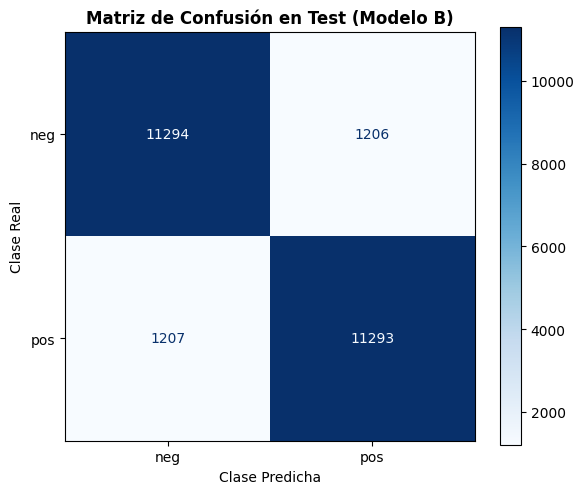

In [ ]:
# 1. Transformar el conjunto de test usando el vectorizador del mejor modelo (Modelo B)
XB_test = tfidf_B.transform(test["clean_neg"])
y_test = test["sentiment"]

# 2. Evaluar el mejor modelo en el conjunto de Test
print("=== EVALUACIÓN DEFINITIVA DEL MEJOR MODELO (MODELO B) EN TEST ===")
pred_test_B = evaluar(lr_B, XB_test, y_test, "Modelo B - Test (con negación)")

print("\nReporte de Clasificación en Test:")
print(classification_report(y_test, pred_test_B, target_names=["neg", "pos"]))

# 3. Calcular y graficar la matriz de confusión para el conjunto de Test
cm_test_B = confusion_matrix(y_test, pred_test_B)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_test_B, display_labels=["neg", "pos"])
disp.plot(ax=ax, cmap=plt.cm.Blues, values_format='d')
ax.set_title('Matriz de Confusión en Test (Modelo B)', fontsize=12, fontweight='bold')
ax.set_xlabel('Clase Predicha')
ax.set_ylabel('Clase Real')
plt.tight_layout()
plt.show()

## Experimento control
"Experimento control: Vecinos más cercanos y analogías en word2vec (good <-> great); las palabras con pesos más positivos y más negativos en la regresión logistica deben ser interpretables"

In [ ]:
# ===== EXPERIMENTO CONTROL (1/2): vecinos más cercanos en word2vec =====
palabras_control = ["good", "great", "bad", "terrible", "boring", "funny", "excellent"]

for p in palabras_control:
    if p in w2v.key_to_index:
        vecinos = w2v.most_similar(p, topn=8)
        print(f"{p:<10} → " + ", ".join(f"{w} ({s:.2f})" for w, s in vecinos))
    else:
        print(f"{p}: fuera del vocabulario")

print("\nSimilitud coseno entre pares de palabras:")
pares = [("good", "great"), ("good", "excellent"), ("bad", "terrible"),
         ("good", "bad"), ("great", "terrible"), ("good", "table")]
tabla_sim = pd.DataFrame(
    [(a, b, w2v.similarity(a, b)) for a, b in pares],
    columns=["palabra_1", "palabra_2", "coseno"]
).round(3)
display(tabla_sim)

good       → great (0.73), bad (0.72), terrific (0.69), decent (0.68), nice (0.68), excellent (0.64), fantastic (0.64), better (0.61)
great      → terrific (0.80), fantastic (0.79), tremendous (0.77), wonderful (0.76), good (0.73), incredible (0.70), marvelous (0.70), phenomenal (0.68)
bad        → good (0.72), terrible (0.68), horrible (0.67), Bad (0.67), lousy (0.66), crummy (0.57), horrid (0.57), awful (0.55)
terrible   → horrible (0.92), horrendous (0.85), dreadful (0.80), awful (0.75), horrid (0.72), atrocious (0.69), horrific (0.68), bad (0.68)
boring     → dull (0.74), uninteresting (0.70), monotonous (0.68), bored (0.65), bland (0.63), tedious (0.63), unexciting (0.62), tiresome (0.61)
funny      → hilarious (0.80), humorous (0.73), hilariously_funny (0.72), amusing (0.71), found_loophole_Conk (0.70), goofy (0.70), comical (0.69), witty (0.69)
excellent  → terrific (0.74), superb (0.71), exceptional (0.68), fantastic (0.68), good (0.64), great (0.61), Excellent (0.61), impeccab

,palabra_1,palabra_2,coseno
0,good,great,0.729
1,good,excellent,0.644
2,bad,terrible,0.683
3,good,bad,0.719
4,great,terrible,0.543
5,good,table,0.164


In [ ]:
# ===== EXPERIMENTO CONTROL (2/2): analogías =====
def analogia(a, b, c, topn=5):
    """a es a b como c es a ?   (calcula b - a + c)"""
    res = w2v.most_similar(positive=[b, c], negative=[a], topn=topn)
    print(f"{a} : {b} :: {c} : ?  →  " + ", ".join(f"{w} ({s:.2f})" for w, s in res))

analogia("man", "king", "woman")      # control clásico de word2vec (esperado: queen)
analogia("good", "great", "bad")      # intensidad: good→great como bad→? (terrible, awful...)
analogia("good", "better", "bad")     # comparativo (esperado: worse)
analogia("good", "best", "bad")       # superlativo (esperado: worst)
analogia("apple", "red", "banana")      # antónimo: good→bad como great→? (terrible, awful...)
analogia("man", "attractive", "woman")      # antónimo: good→bad como great→? (terrible, awful...)
analogia("good", "bad", "great")      # antónimo: good→bad como great→? (terrible, awful...)

man : king :: woman : ?  →  queen (0.71), monarch (0.62), princess (0.59), crown_prince (0.55), prince (0.54)
good : great :: bad : ?  →  terrible (0.71), horrible (0.64), unbelievable (0.55), fantastic (0.54), horrendous (0.53)
good : better :: bad : ?  →  worse (0.73), uglier (0.57), sooner (0.53), dumber (0.52), differently (0.52)
good : best :: bad : ?  →  worst (0.68), dumbest (0.53), lousiest (0.52), ugliest (0.51), nastiest (0.51)
apple : red :: banana : ?  →  yellow (0.59), blue (0.52), pink (0.45), purple (0.44), bright_orange (0.42)
man : attractive :: woman : ?  →  unattractive (0.63), alluring (0.61), desirable (0.55), Attractive (0.51), attractive_proposition (0.50)
good : bad :: great : ?  →  terrible (0.71), horrible (0.64), unbelievable (0.55), fantastic (0.54), horrendous (0.53)


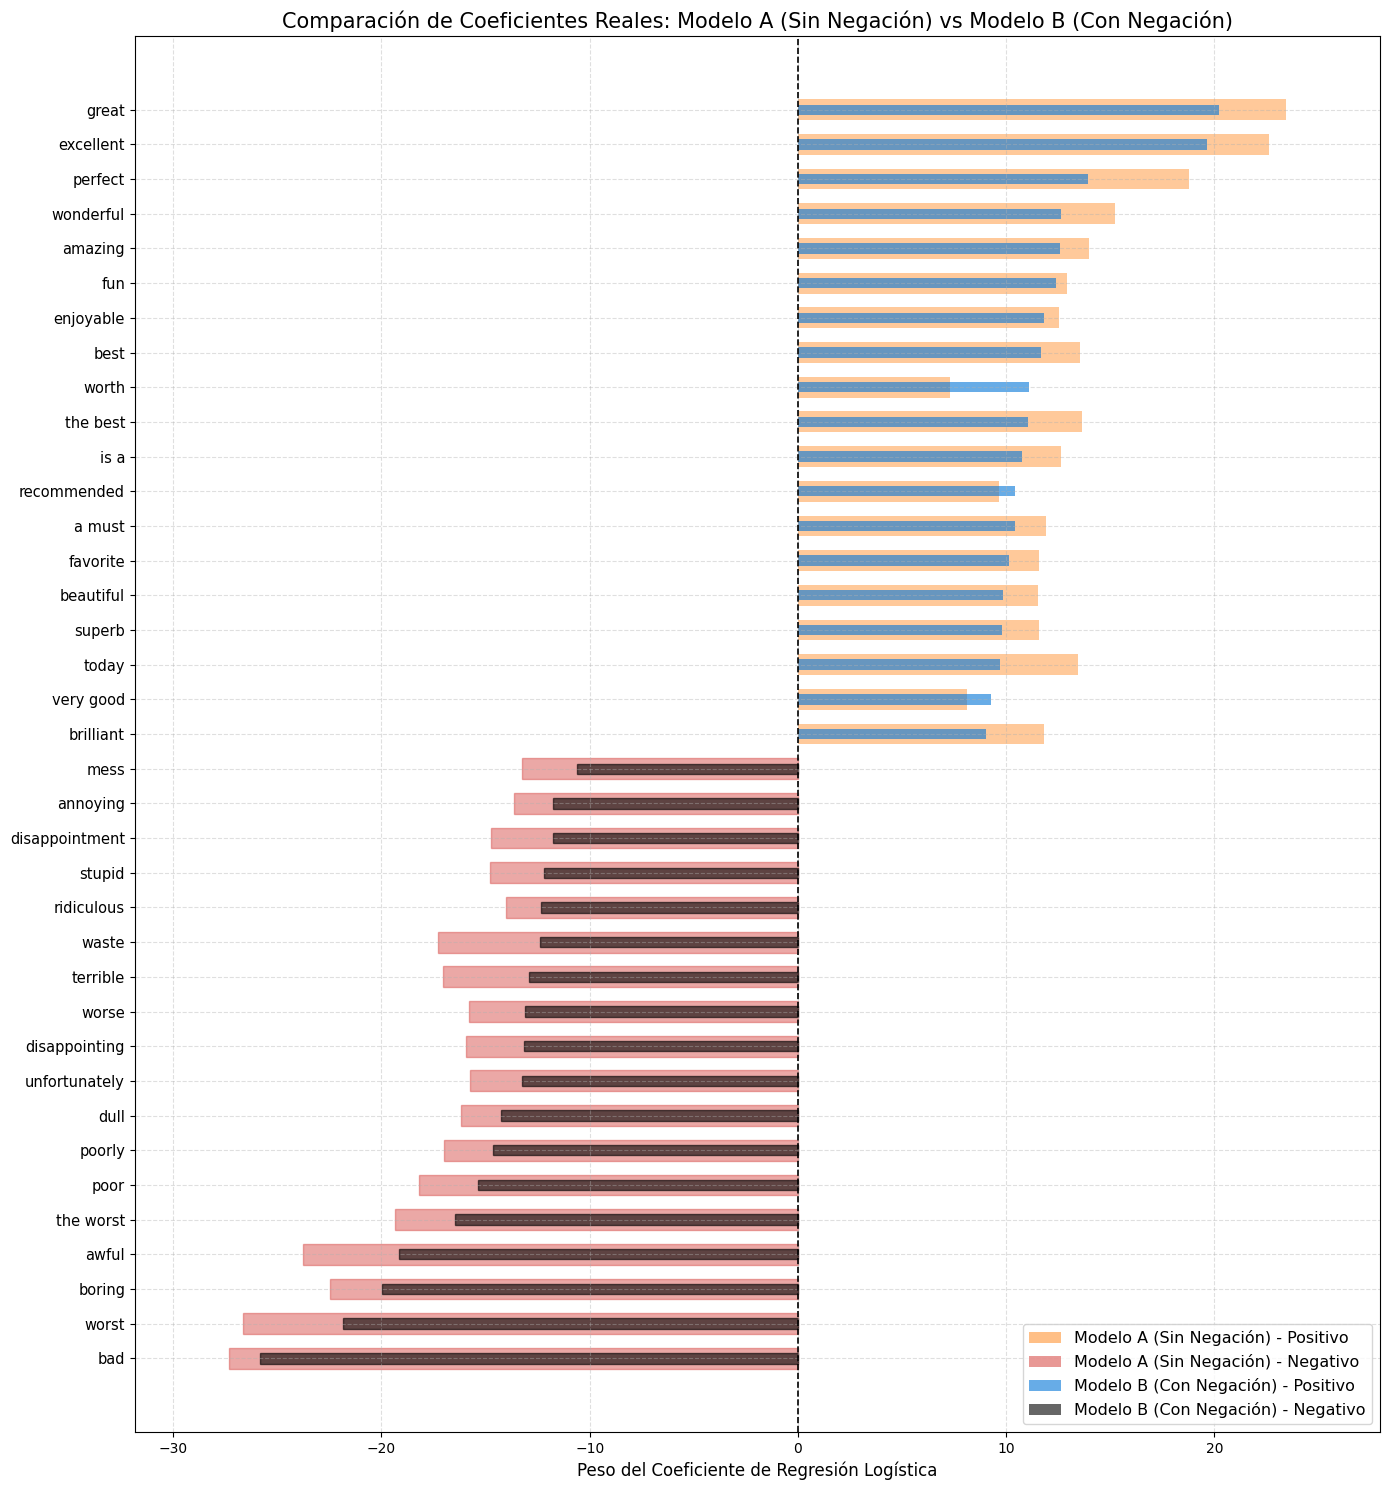

,Palabra de interés,Coeficiente Modelo A (Sin Neg),Coeficiente Modelo B (Con Neg)
0,worth,7.3106,11.1029
1,very good,8.1344,9.2863
2,a must,11.9330,10.4165
3,disappointment,-14.7293,-11.7851
4,beautiful,11.5147,9.8450
5,mess,-13.2462,-10.6179
6,today,13.4413,9.7035
7,favorite,11.5729,10.1296
8,annoying,-13.6297,-11.7726
9,dull,-16.1785,-14.2571


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch

# 1. Recuperar los top weights de ambos modelos
def obtener_top_pesos(modelo, vectorizador, k=15):
    nombres = np.array(vectorizador.get_feature_names_out())
    coefs = modelo.coef_[0]
    orden = np.argsort(coefs)___
    idx = np.concatenate([orden[:k], orden[-k:]])
    return pd.DataFrame({"término": nombres[idx], "peso": coefs[idx]})

df_A = obtener_top_pesos(lr_A, tfidf_A, k=15).rename(columns={"peso": "Modelo A"})
df_B = obtener_top_pesos(lr_B, tfidf_B, k=15).rename(columns={"peso": "Modelo B"})

# Unimos ambos conjuntos de términos
df_union = pd.merge(df_A, df_B, on="término", how="outer").fillna(0)

# 2. Obtener diccionarios de pesos completos de cada modelo
coefs_completos_A = dict(zip(tfidf_A.get_feature_names_out(), lr_A.coef_[0]))
coefs_completos_B = dict(zip(tfidf_B.get_feature_names_out(), lr_B.coef_[0]))

# Lista específica de palabras que el usuario quiere comparar explícitamente con sus valores reales
palabras_comparar = ["worth", "very good", "a must", "disappointment", "beautiful", "mess", "today", "favorite", "annoying", "dull"]

# Aseguramos que todas estas palabras de interés estén incluidas en nuestro DataFrame de graficación
for p in palabras_comparar:
    if p not in df_union["término"].values:
        peso_A = coefs_completos_A.get(p, 0.0)
        peso_B = coefs_completos_B.get(p, 0.0)
        nuevo_registro = pd.DataFrame([{"término": p, "Modelo A": peso_A, "Modelo B": peso_B}])
        df_union = pd.concat([df_union, nuevo_registro], ignore_index=True)

# Si hay registros duplicados tras forzar la inclusión, los eliminamos
df_union = df_union.drop_duplicates(subset="término")

# 3. Rellenar los valores reales completos para todos los términos de la unión
df_union["Modelo A"] = df_union["término"].map(lambda x: coefs_completos_A.get(x, 0.0))
df_union["Modelo B"] = df_union["término"].map(lambda x: coefs_completos_B.get(x, 0.0))

# Ordenar por el peso del Modelo B para mantener una estructura visual uniforme
df_union = df_union.sort_values(by="Modelo B", ascending=True).reset_index(drop=True)

# 4. Configurar y construir el gráfico
ind = np.arange(len(df_union))
ancho = 0.6

fig, ax = plt.subplots(figsize=(14, 15))

# Graficar barras (solapadas con transparencia)
bars_A = ax.barh(ind, df_union["Modelo A"], ancho, label="Modelo A", color="#FF9536", alpha=0.5, align='center')
bars_B = ax.barh(ind, df_union["Modelo B"], ancho * 0.5, label="Modelo B", color="#0275d8", alpha=0.6, align='center')

# Colores distintivos según polaridad para cada barra
for i, (bar_a, bar_b) in enumerate(zip(bars_A, bars_B)):
    val_a = df_union["Modelo A"].iloc[i]
    val_b = df_union["Modelo B"].iloc[i]

    if val_a < 0:
        bar_a.set_color("#d9534f")
    if val_b < 0:
        bar_b.set_color("#000000")

"""
# Agregar los valores numéricos ausentes directamente al final de cada barra para una fácil lectura
for i in range(len(df_union)):
    val_a = df_union["Modelo A"].iloc[i]
    val_b = df_union["Modelo B"].iloc[i]
    term = df_union["término"].iloc[i]

    # Resaltar en negrita si es una de las palabras específicas de interés del usuario
    es_palabra_clave = term in palabras_comparar
    color_texto = 'black' if es_palabra_clave else '#555555'
    peso_fuente = 'bold' if es_palabra_clave else 'normal'

    # Etiqueta de Modelo A (línea superior)
    desplazamiento_a = 0.5 if val_a >= 0 else -3.2
    ax.text(val_a + desplazamiento_a, i + 0.15, f"A: {val_a:.2f}",
            va='center', ha='left', fontsize=8.5, color=color_texto, fontweight=peso_fuente)

    # Etiqueta de Modelo B (línea inferior)
    desplazamiento_b = 0.5 if val_b >= 0 else -3.2
    ax.text(val_b + desplazamiento_b, i - 0.18, f"B: {val_b:.2f}",
            va='center', ha='left', fontsize=8.5, color=color_texto, fontweight=peso_fuente)
"""
# Detalles estéticos del gráfico
ax.axvline(0, color="black", lw=1.2, linestyle="--")
ax.set_yticks(ind)
ax.set_yticklabels(df_union["término"], fontsize=10.5)
ax.set_title("Comparación de Coeficientes Reales: Modelo A (Sin Negación) vs Modelo B (Con Negación)", fontsize=15)
ax.set_xlabel("Peso del Coeficiente de Regresión Logística", fontsize=12)
ax.set_xlim(df_union["Modelo A"].min() - 4.5, df_union["Modelo A"].max() + 4.5)
ax.grid(True, linestyle="--", alpha=0.4)

# Leyenda personalizada
legend_elements = [
    Patch(facecolor='#FF9536', alpha=0.6, label='Modelo A (Sin Negación) - Positivo'),
    Patch(facecolor='#d9534f', alpha=0.6, label='Modelo A (Sin Negación) - Negativo'),
    Patch(facecolor='#0275d8', alpha=0.6, label='Modelo B (Con Negación) - Positivo'),
    Patch(facecolor='#000000', alpha=0.6, label='Modelo B (Con Negación) - Negativo')
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=11.5)

plt.tight_layout()
plt.show()

# Mostrar resumen en una tabla de Pandas justo debajo
filas_resumen = []
for p in palabras_comparar:
    filas_resumen.append({
        "Palabra de interés": p,
        "Coeficiente Modelo A (Sin Neg)": round(coefs_completos_A.get(p, 0.0), 4),
        "Coeficiente Modelo B (Con Neg)": round(coefs_completos_B.get(p, 0.0), 4)
    })
display(pd.DataFrame(filas_resumen))